# 001b · Eyes open vs eyes closed: does frozen REVE see alpha?

In healthy adults, closing the eyes raises posterior alpha (8–13 Hz) roughly 10×. A model that "understands" EEG
should separate the two states easily, and ideally from the occipital signal, not from the absence of blinks.

**Tests**
1. Is alpha actually there? Per subject/run alpha reactivity (sanity check on the labels).
2. Linear probe, leave-one-subject-out: REVE with *all* channels vs REVE with *posterior channels only*
   (no frontal/eye information) vs classical features (a single occipital alpha number; band power).
3. Does the REVE embedding encode alpha power? (Ridge regression embedding → occipital alpha.)

Run `extract_eyes.py` first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import balanced_accuracy_score, r2_score, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from neuro_expeditions import DATA_DIR

CACHE = DATA_DIR / "cache" / "001-reve-artifacts" / "eyes"
BANDS = ["delta", "theta", "alpha", "beta", "gamma"]
OCC = ["O1", "O2", "Oz"]
POSTERIOR = ["P3", "P4", "P5", "P6", "P7", "P8", "Pz", "POz", "PO3", "PO4", "PO5", "PO6", "PO7", "PO8", "Oz", "O1", "O2"]
plt.rcParams["figure.dpi"] = 110

In [2]:
rows = []
for f in sorted(CACHE.glob("sub*_run*.npz")):
    z = np.load(f)
    if not len(z["labels"]):
        continue
    ch = list(z["ch_names"])
    bp = z["bandpower"].reshape(len(z["labels"]), len(ch), len(BANDS))
    occ, post, fp = [ch.index(c) for c in OCC], [ch.index(c) for c in POSTERIOR], [ch.index(c) for c in ("Fp1", "Fp2")]
    rows.append(pd.DataFrame({
        "subject": int(f.stem.split("_")[0][3:]), "run": int(f.stem[-2:]),
        "closed": (z["labels"] == "clean_eyes_closed").astype(int),
        "occ_alpha": bp[:, occ, 2].mean(1),           # log10 power, occipital alpha
        "fp_delta": bp[:, fp, 0].mean(1),             # log10 power, frontal delta (blinks)
        "bp_all": list(bp.reshape(len(bp), -1)),
        "bp_post": list(bp[:, post].reshape(len(bp), -1)),
        "reve_all": list(z["reve_all_attn"]), "reve_post": list(z["reve_post_attn"]),
        "reve_all_mean": list(z["reve_all_mean"]), "reve_post_mean": list(z["reve_post_mean"]),
    }))
df = pd.concat(rows, ignore_index=True)
# Keep subjects that have both conditions
both = df.groupby("subject").closed.agg(["min", "max"])
df = df[df.subject.isin(both.index[(both["min"] == 0) & (both["max"] == 1)])].reset_index(drop=True)
print(f"{len(df)} windows, {df.subject.nunique()} subjects, {df.closed.mean():.0%} eyes closed")

27867 windows, 28 subjects, 46% eyes closed


## 1. Is the alpha there?
Occipital alpha, eyes closed minus eyes open (log10; +1 = 10× more power). Frontal delta drop = fewer blinks = eyes really shut.

non-reactive subjects: [6]
runs where 'eyes closed' shows neither alpha rise nor fewer blinks (suspect labels):


,,alpha_EC_minus_EO,blink_drop
subject,run,,
1,1,-0.07,0.25
26,6,-0.62,-0.17


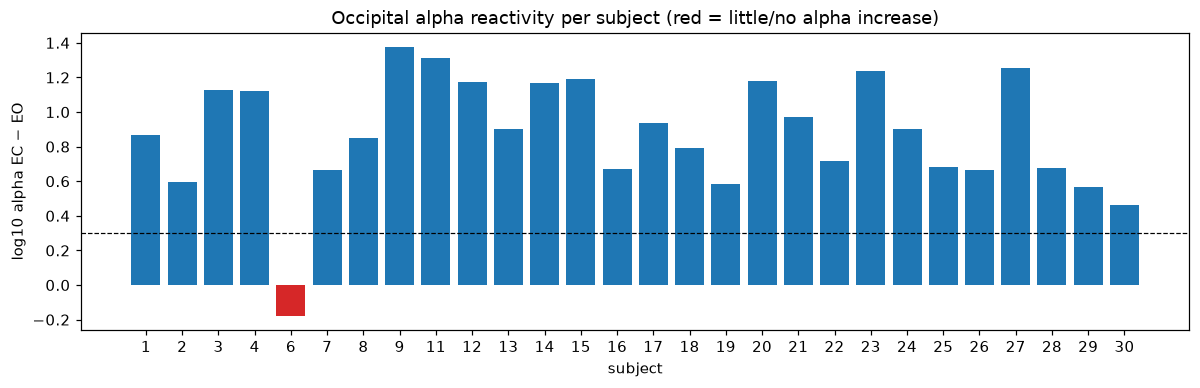

In [3]:
def reactivity(g):
    eo, ec = g[g.closed == 0], g[g.closed == 1]
    return pd.Series({"alpha_EC_minus_EO": ec.occ_alpha.mean() - eo.occ_alpha.mean(),
                      "blink_drop": eo.fp_delta.mean() - ec.fp_delta.mean()})

per_sub = df.groupby("subject").apply(reactivity)
per_run = df.groupby(["subject", "run"]).apply(reactivity).dropna()
REACTIVE = 0.3   # > 2x alpha increase
per_sub["alpha_reactive"] = per_sub.alpha_EC_minus_EO > REACTIVE

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(per_sub.index.astype(str), per_sub.alpha_EC_minus_EO,
       color=np.where(per_sub.alpha_reactive, "tab:blue", "tab:red"))
ax.axhline(REACTIVE, ls="--", c="k", lw=0.8)
ax.set(xlabel="subject", ylabel="log10 alpha EC − EO", title="Occipital alpha reactivity per subject (red = little/no alpha increase)")
print("non-reactive subjects:", per_sub.index[~per_sub.alpha_reactive].tolist())
print("runs where 'eyes closed' shows neither alpha rise nor fewer blinks (suspect labels):")
display(per_run[(per_run.alpha_EC_minus_EO < REACTIVE) & (per_run.blink_drop < 0.3)].round(2))

## 2. Linear probe, leave-one-subject-out
`per-subject norm` z-scores each feature within a subject (label-free), which removes person-level offsets such as overall alpha amplitude.

In [4]:
def subject_zscore(X, groups):
    X = X.copy()
    for g in np.unique(groups):
        m = groups == g
        X[m] = (X[m] - X[m].mean(0)) / (X[m].std(0) + 1e-8)
    return X

def probe(X, df=df, norm=False):
    y, g = df.closed.values, df.subject.values
    if norm:
        X = subject_zscore(X, g)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced"))
    return cross_val_predict(clf, X, y, groups=g, cv=LeaveOneGroupOut(), method="predict_proba", n_jobs=-1)[:, 1]

FEATURES = {
    "occipital alpha (1 number)": lambda d: d[["occ_alpha"]].values,
    "band power, posterior": lambda d: np.stack(d.bp_post),
    "band power, all channels": lambda d: np.stack(d.bp_all),
    "REVE, posterior channels only": lambda d: np.stack(d.reve_post),
    "REVE, all channels": lambda d: np.stack(d.reve_all),
}
probs = {(name, norm): probe(fn(df), norm=norm) for name, fn in FEATURES.items() for norm in (False, True)}

reactive_mask = df.subject.map(per_sub.alpha_reactive).values
def scores(p, m=slice(None)):
    y = df.closed.values[m]
    return balanced_accuracy_score(y, p[m] > 0.5), roc_auc_score(y, p[m])

table = pd.DataFrame([
    {"features": name, "per-subject norm": norm,
     "bal_acc (all)": scores(p)[0], "AUROC (all)": scores(p)[1],
     "bal_acc (alpha-reactive subj.)": scores(p, reactive_mask)[0],
     "bal_acc (non-reactive subj.)": scores(p, ~reactive_mask)[0] if (~reactive_mask).any() else np.nan}
    for (name, norm), p in probs.items()]).set_index(["features", "per-subject norm"])
table.round(3)

/Users/vinicius.duarte/Library/Caches/pypoetry/virtualenvs/neuro-expeditions-DOJ7ouU9-py3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/Users/vinicius.duarte/Library/Caches/pypoetry/virtualenvs/neuro-expeditions-DOJ7ouU9-py3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/Users/vinicius.duarte/Library/Caches/pypoetry/virtualenvs/neuro-expeditions-DOJ7ouU9-py3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


bal_acc (all)  AUROC (all)  \
features                      per-subject norm                               
occipital alpha (1 number)    False                     0.841        0.875   
                              True                      0.876        0.905   
band power, posterior         False                     0.812        0.882   
                              True                      0.890        0.935   
band power, all channels      False                     0.848        0.930   
                              True                      0.892        0.948   
REVE, posterior channels only False                     0.818        0.878   
                              True                      0.864        0.925   
REVE, all channels            False                     0.866        0.933   
                              True                      0.918        0.960   

                                                bal_acc (alpha-reactive subj.)  \
features                      per-subject norm                                   
occipital alpha (1 number)    False                                      0.861   
                              True                                       0.907   
band power, posterior         False                                      0.831   
                              True                                       0.908   
band power, all channels      False                                      0.864   
                              True                                       0.912   
REVE, posterior channels only False                                      0.837   
                              True                                       0.882   
REVE, all channels            False                                      0.883   
                              True                                       0.925   

                                                bal_acc (non-reactive subj.)  
features                      per-subject norm                                
occipital alpha (1 number)    False                                    0.500  
                              True                                     0.300  
band power, posterior         False                                    0.503  
                              True                                     0.544  
band power, all channels      False                                    0.583  
                              True                                     0.532  
REVE, posterior channels only False                                    0.502  
                              True                                     0.527  
REVE, all channels            False                                    0.585  
                              True                                     0.789

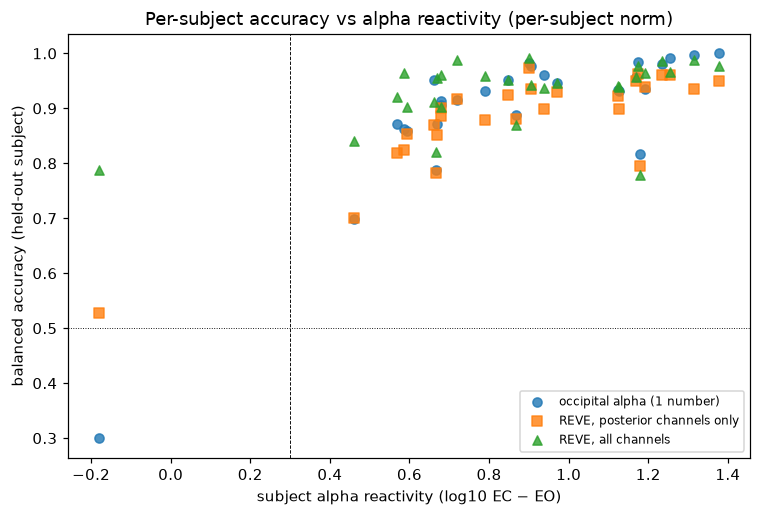

In [5]:
# Per subject: accuracy vs how much alpha that person shows
acc = pd.DataFrame({name: df.assign(p=probs[(name, True)] > 0.5).groupby("subject").apply(
    lambda d: balanced_accuracy_score(d.closed, d.p)) for name in FEATURES})
fig, ax = plt.subplots(figsize=(8, 5))
for name, marker in zip(["occipital alpha (1 number)", "REVE, posterior channels only", "REVE, all channels"], "os^"):
    ax.scatter(per_sub.alpha_EC_minus_EO, acc[name], marker=marker, label=name, alpha=0.8)
ax.axhline(0.5, c="k", lw=0.6, ls=":"); ax.axvline(REACTIVE, c="k", lw=0.6, ls="--")
ax.set(xlabel="subject alpha reactivity (log10 EC − EO)", ylabel="balanced accuracy (held-out subject)",
       title="Per-subject accuracy vs alpha reactivity (per-subject norm)")
ax.legend(fontsize=8)

## 3. Does the REVE embedding encode alpha power?
Ridge regression from the (posterior-only) embedding to occipital log-alpha, leave-one-subject-out.

/Users/vinicius.duarte/Library/Caches/pypoetry/virtualenvs/neuro-expeditions-DOJ7ouU9-py3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


R² (within-subject occipital alpha) from REVE posterior: 0.766   from REVE all-channel: 0.812


[Text(0.5, 0, 'actual occipital alpha (z, within subject)'),
 Text(0, 0.5, 'predicted from REVE embedding'),
 Text(0.5, 1.0, 'REVE posterior → alpha, R²=0.77\n(red = eyes closed, blue = open)')]

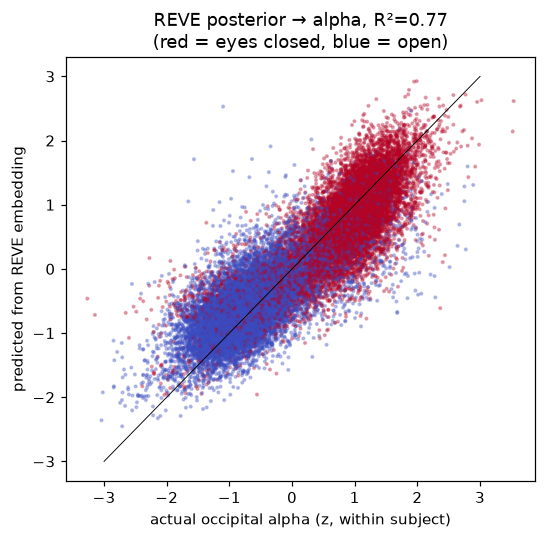

In [6]:
def ridge_r2(X, y, groups):
    reg = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 12)))
    pred = cross_val_predict(reg, X, y, groups=groups, cv=LeaveOneGroupOut(), n_jobs=-1)
    return r2_score(y, pred), pred

g = df.subject.values
y_alpha = subject_zscore(df[["occ_alpha"]].values, g)[:, 0]   # within-subject alpha fluctuations
r2_post, pred_post = ridge_r2(subject_zscore(np.stack(df.reve_post), g), y_alpha, g)
r2_all, _ = ridge_r2(subject_zscore(np.stack(df.reve_all), g), y_alpha, g)
print(f"R² (within-subject occipital alpha) from REVE posterior: {r2_post:.3f}   from REVE all-channel: {r2_all:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_alpha, pred_post, s=3, alpha=0.3, c=df.closed, cmap="coolwarm")
ax.plot([-3, 3], [-3, 3], c="k", lw=0.6)
ax.set(xlabel="actual occipital alpha (z, within subject)", ylabel="predicted from REVE embedding",
       title=f"REVE posterior → alpha, R²={r2_post:.2f}\n(red = eyes closed, blue = open)")

## Notes
Findings go in `README.md` → *Log*.